# 5. The same analysis on three shops

One gift shop from 2011 is a thin base for any claim. So the same code, unchanged, runs here on two newer and very different sets of sales.

| Shop | What it is | A product is |
| --- | --- | --- |
| UK gift retailer | One online shop selling mostly to businesses, 2010 to 2011 | A single item |
| Amazon shoppers | 5,013 US shoppers who shared their Amazon order history, 2018 to 2022 | A category, such as pet food |
| US grocery chain | 2,467 households over one year | A type, such as bananas |

The Amazon data has no order numbers, so one shopper on one day counts as one order. The grocery publisher shifted the dates to 2017.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shoplens.clean import SHOPS, load, clean, open_shop
from shoplens.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, [JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS
from shoplens.segmentation import summarize, group, by_group
from shoplens.market_basket import pairs, rules, families
from shoplens.forward import groups_next, pairs_next

shops = {}
for name in SHOPS:
    sales = open_shop(name)[0]
    customers = summarize(sales)
    customers["group"] = group(customers)
    shops[name] = dict(sales=sales, customers=customers, groups=by_group(customers), pairs=pairs(sales), sign=SHOPS[name]["money"],
                       groups_next=groups_next(sales), pairs_next=pairs_next(sales))
short = dict(zip(SHOPS, ["UK gift retailer", "Amazon shoppers", "US grocery chain"]))

## Three very different businesses

In [2]:
rows = {}
for name, s in shops.items():
    orders = s["sales"].groupby("order").agg(value=("revenue", "sum"), products=("product", "nunique"))
    rows[short[name]] = {"Customers": f"{len(s['customers']):,}", "Orders": f"{len(orders):,}", "Revenue": f"{s['sign']}{s['sales'].revenue.sum():,.0f}",
                         "Orders per customer": f"{len(orders) / len(s['customers']):.0f}", "Average order": f"{s['sign']}{orders.value.mean():,.0f}",
                         "Products per order": f"{orders.products.mean():.1f}", "From": f"{s['sales'].when.min():%b %Y}", "To": f"{s['sales'].when.max():%b %Y}"}
pd.DataFrame(rows)

,UK gift retailer,Amazon shoppers,US grocery chain
Customers,"4,324","5,013","2,467"
Orders,"18,268","749,808","140,925"
Revenue,"£8,272,854","$38,955,320","$4,186,248"
Orders per customer,4,150,57
Average order,£453,$52,$30
Products per order,21.0,1.9,8.7
From,Dec 2010,Jan 2018,Jan 2017
To,Dec 2011,Oct 2022,Jan 2018


The gift shop's customers place four large orders a year. Amazon shoppers place about 150 small ones over five years. Grocery households shop more than once a week.

## Customer segmentation

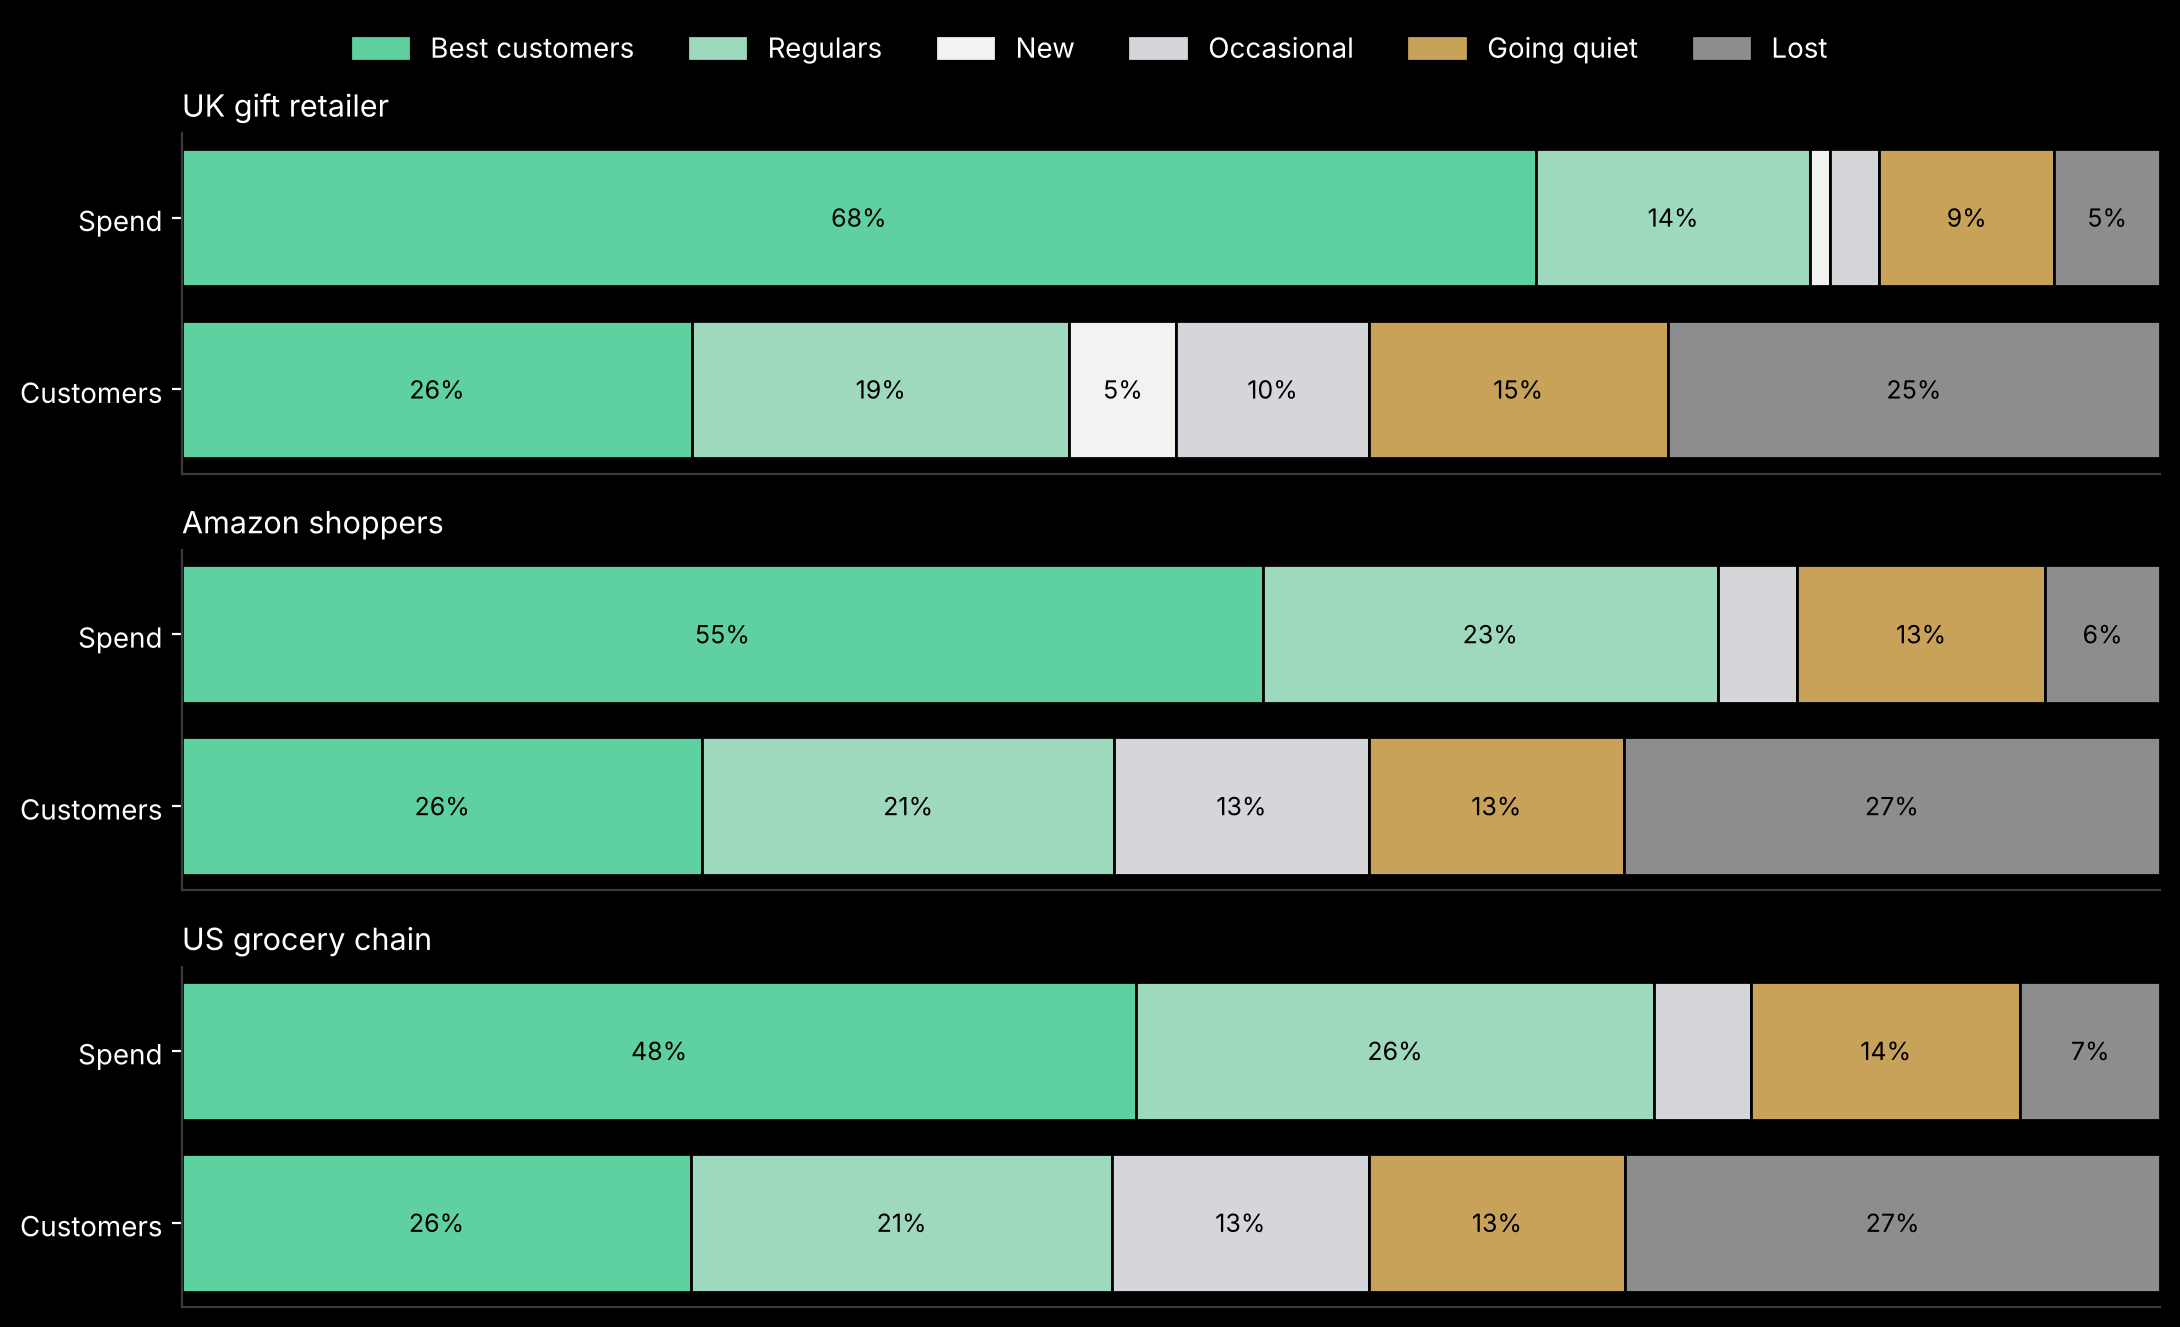

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.4))
for ax, (name, s) in zip(axes, shops.items()):
    for row, column in enumerate(["share_of_customers", "share_of_spend"]):
        left = 0
        for g in s["groups"].index:
            v = s["groups"].loc[g, column]
            ax.barh(row, v, left=left, color=COLORS[g], edgecolor="black")
            if v > 0.05:
                ax.text(left + v / 2, row, f"{v:.0%}", ha="center", va="center", color="black", fontsize=9)
            left += v
    ax.set_yticks([0, 1], ["Customers", "Spend"]); ax.set_xlim(0, 1); ax.xaxis.set_visible(False); ax.grid(False); ax.set_title(short[name], loc="left", fontsize=11)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[g]) for g in GROUPS], labels=GROUPS, frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(); plt.show()

The same shape shows up everywhere. About a quarter of customers are Best customers, and they bring in half to two thirds of the money. The share is highest at the gift shop, where a few business buyers place very large orders.

Almost nobody lands in New at Amazon or the grocery chain. Those customers were all buying from the start of the data.

## Did the segments hold up?

The last 90 days of each shop are hidden, the segments are built from the earlier sales, and the hidden days are the test.

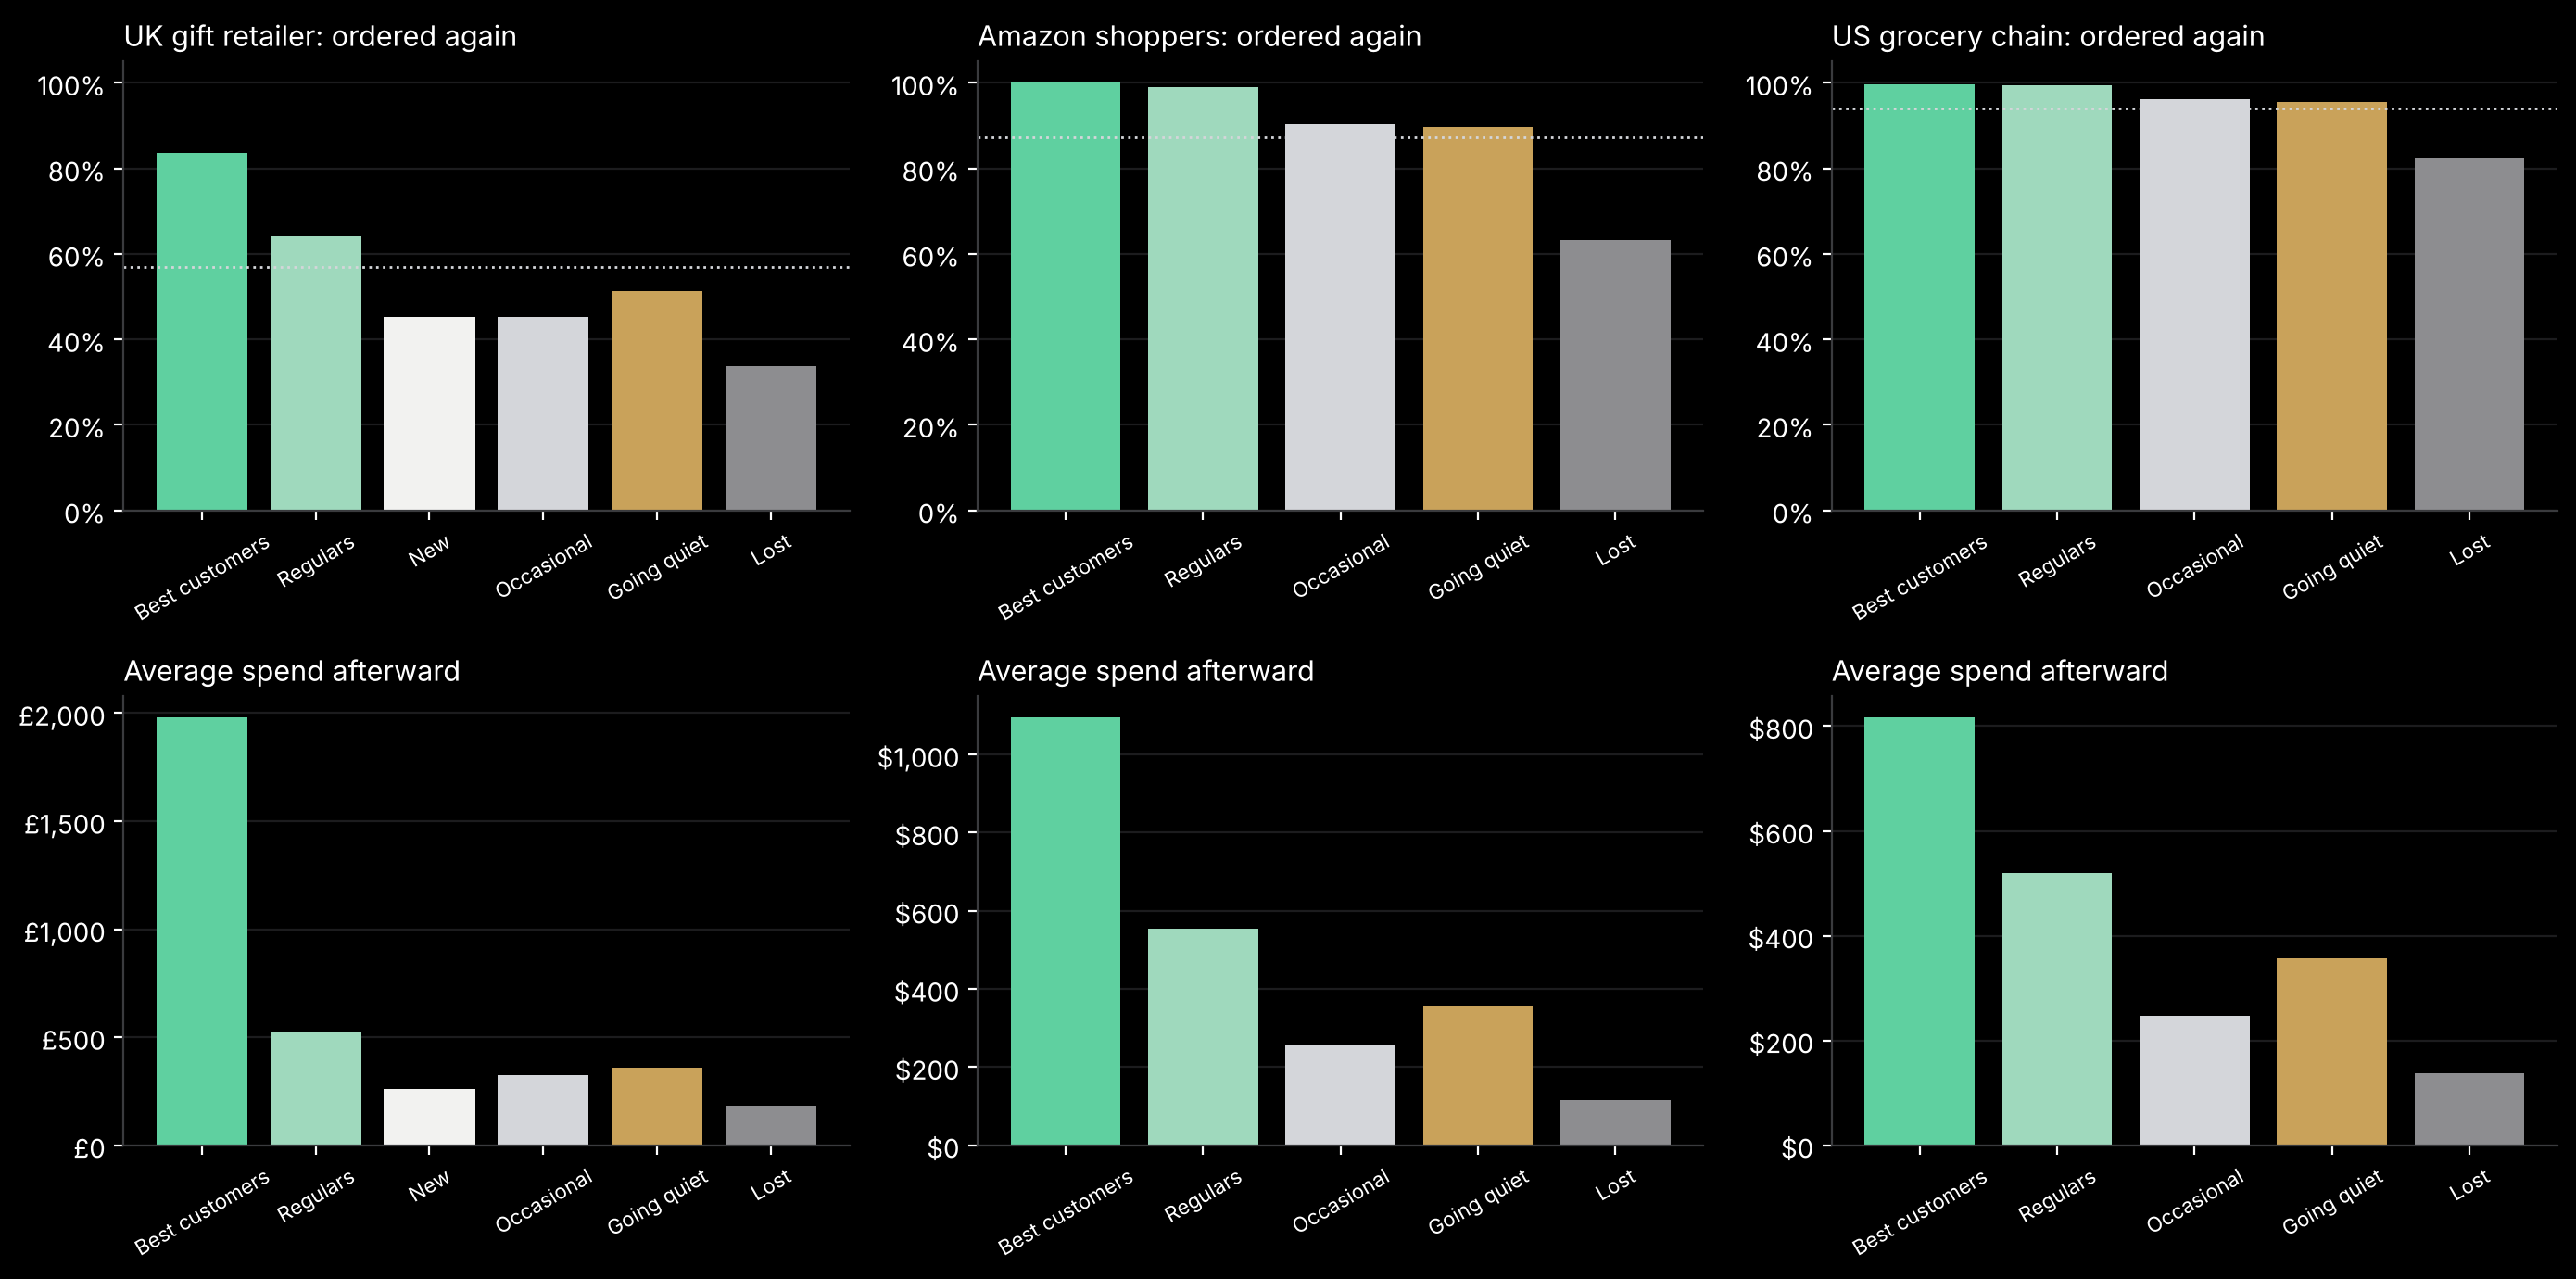

,UK gift retailer,Amazon shoppers,US grocery chain
group,,,
Best customers,84%,100%,100%
Regulars,64%,99%,99%
New,45%,,
Occasional,45%,90%,96%
Going quiet,51%,90%,96%
Lost,34%,63%,82%
Everyone,57%,87%,94%


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for column, (name, s) in enumerate(shops.items()):
    table = s["groups_next"]; each = table.drop("Everyone")
    axes[0, column].bar(each.index, each.came_back, color=[COLORS[g] for g in each.index])
    axes[0, column].axhline(table.loc["Everyone", "came_back"], color=SILVER, lw=1, ls=":"); axes[0, column].set_ylim(0, 1.05)
    axes[0, column].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axes[0, column].set_title(f"{short[name]}: ordered again", loc="left", fontsize=11)
    axes[1, column].bar(each.index, each.average_spend_after, color=[COLORS[g] for g in each.index])
    axes[1, column].yaxis.set_major_formatter(lambda v, _, sign=s["sign"]: f"{sign}{v:,.0f}"); axes[1, column].set_title("Average spend afterward", loc="left", fontsize=11)
for ax in axes.ravel():
    ax.tick_params(axis="x", rotation=30, labelsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
pd.DataFrame({short[n]: s["groups_next"].came_back for n, s in shops.items()}).reindex(GROUPS + ["Everyone"]).style.format("{:.0%}", na_rep="")

The segments sorted customers in the same order at all three shops, on both measures.

What changes is how much is at stake. At the gift shop, coming back at all is the question: 84 percent of Best customers against 34 percent of Lost. At Amazon and the grocery chain nearly everyone comes back, because buying there is a habit. The segments matter there for spend, where Best customers are worth six to nine times a Lost one, and for the one segment that does leak: Lost.

## Market basket analysis

In [5]:
for name, s in shops.items():
    top = s["pairs"].head(8).assign(pair=lambda t: t.name_a.str.title().str.strip() + "  +  " + t.name_b.str.title().str.strip())[["pair", "together", "lift"]]
    display(top.style.format({"together": "{:,.0f}", "lift": "{:.0f}x"}).hide(axis="index").set_caption(f"{short[name]}: {len(s['pairs']):,} pairs found"))

pair,together,lift
Regency Tea Plate Green + Regency Tea Plate Pink,201,61x
Regency Milk Jug Pink + Regency Sugar Bowl Green,205,52x
Set Of 3 Wooden Stocking Decoration + Set Of 3 Wooden Tree Decorations,181,49x
Regency Tea Plate Roses + Regency Tea Plate Pink,195,49x
"Key Fob , Shed + Key Fob , Back Door",165,49x
Set/10 Pink Polkadot Party Candles + Set/10 Blue Polkadot Party Candles,180,48x
Set Of 3 Wooden Sleigh Decorations + Set Of 3 Wooden Tree Decorations,161,48x
Regency Tea Plate Roses + Regency Tea Plate Green,227,47x


pair,together,lift
Dairy Based Cheese + Bread,"1,565",117x
Dairy Based Cheese + Poultry,"1,258",108x
Bread + Poultry,"1,188",107x
Meat + Poultry,"1,191",100x
Meat + Dairy Based Cheese,"1,422",99x
Vegetable + Poultry,"1,602",96x
Meat + Bread,"1,305",95x
Vegetable + Fruit,"2,430",94x


pair,together,lift
Peaches + Pears,437,60x
Layer Cake Mix + Frosting,"1,187",48x
Baby Food - Beginner + Baby Food Junior All Brands,403,45x
Pears + Fruit Cocktail Fruit Salad,246,45x
Shampoo + Hair Conditioners And Rinses,964,39x
Mexican Seasoning Mixes + Mexican Taco Tostado Shells,445,38x
Peaches + Fruit Cocktail Fruit Salad,263,36x
Razors And Blades + Shave Creams And Powders,203,32x


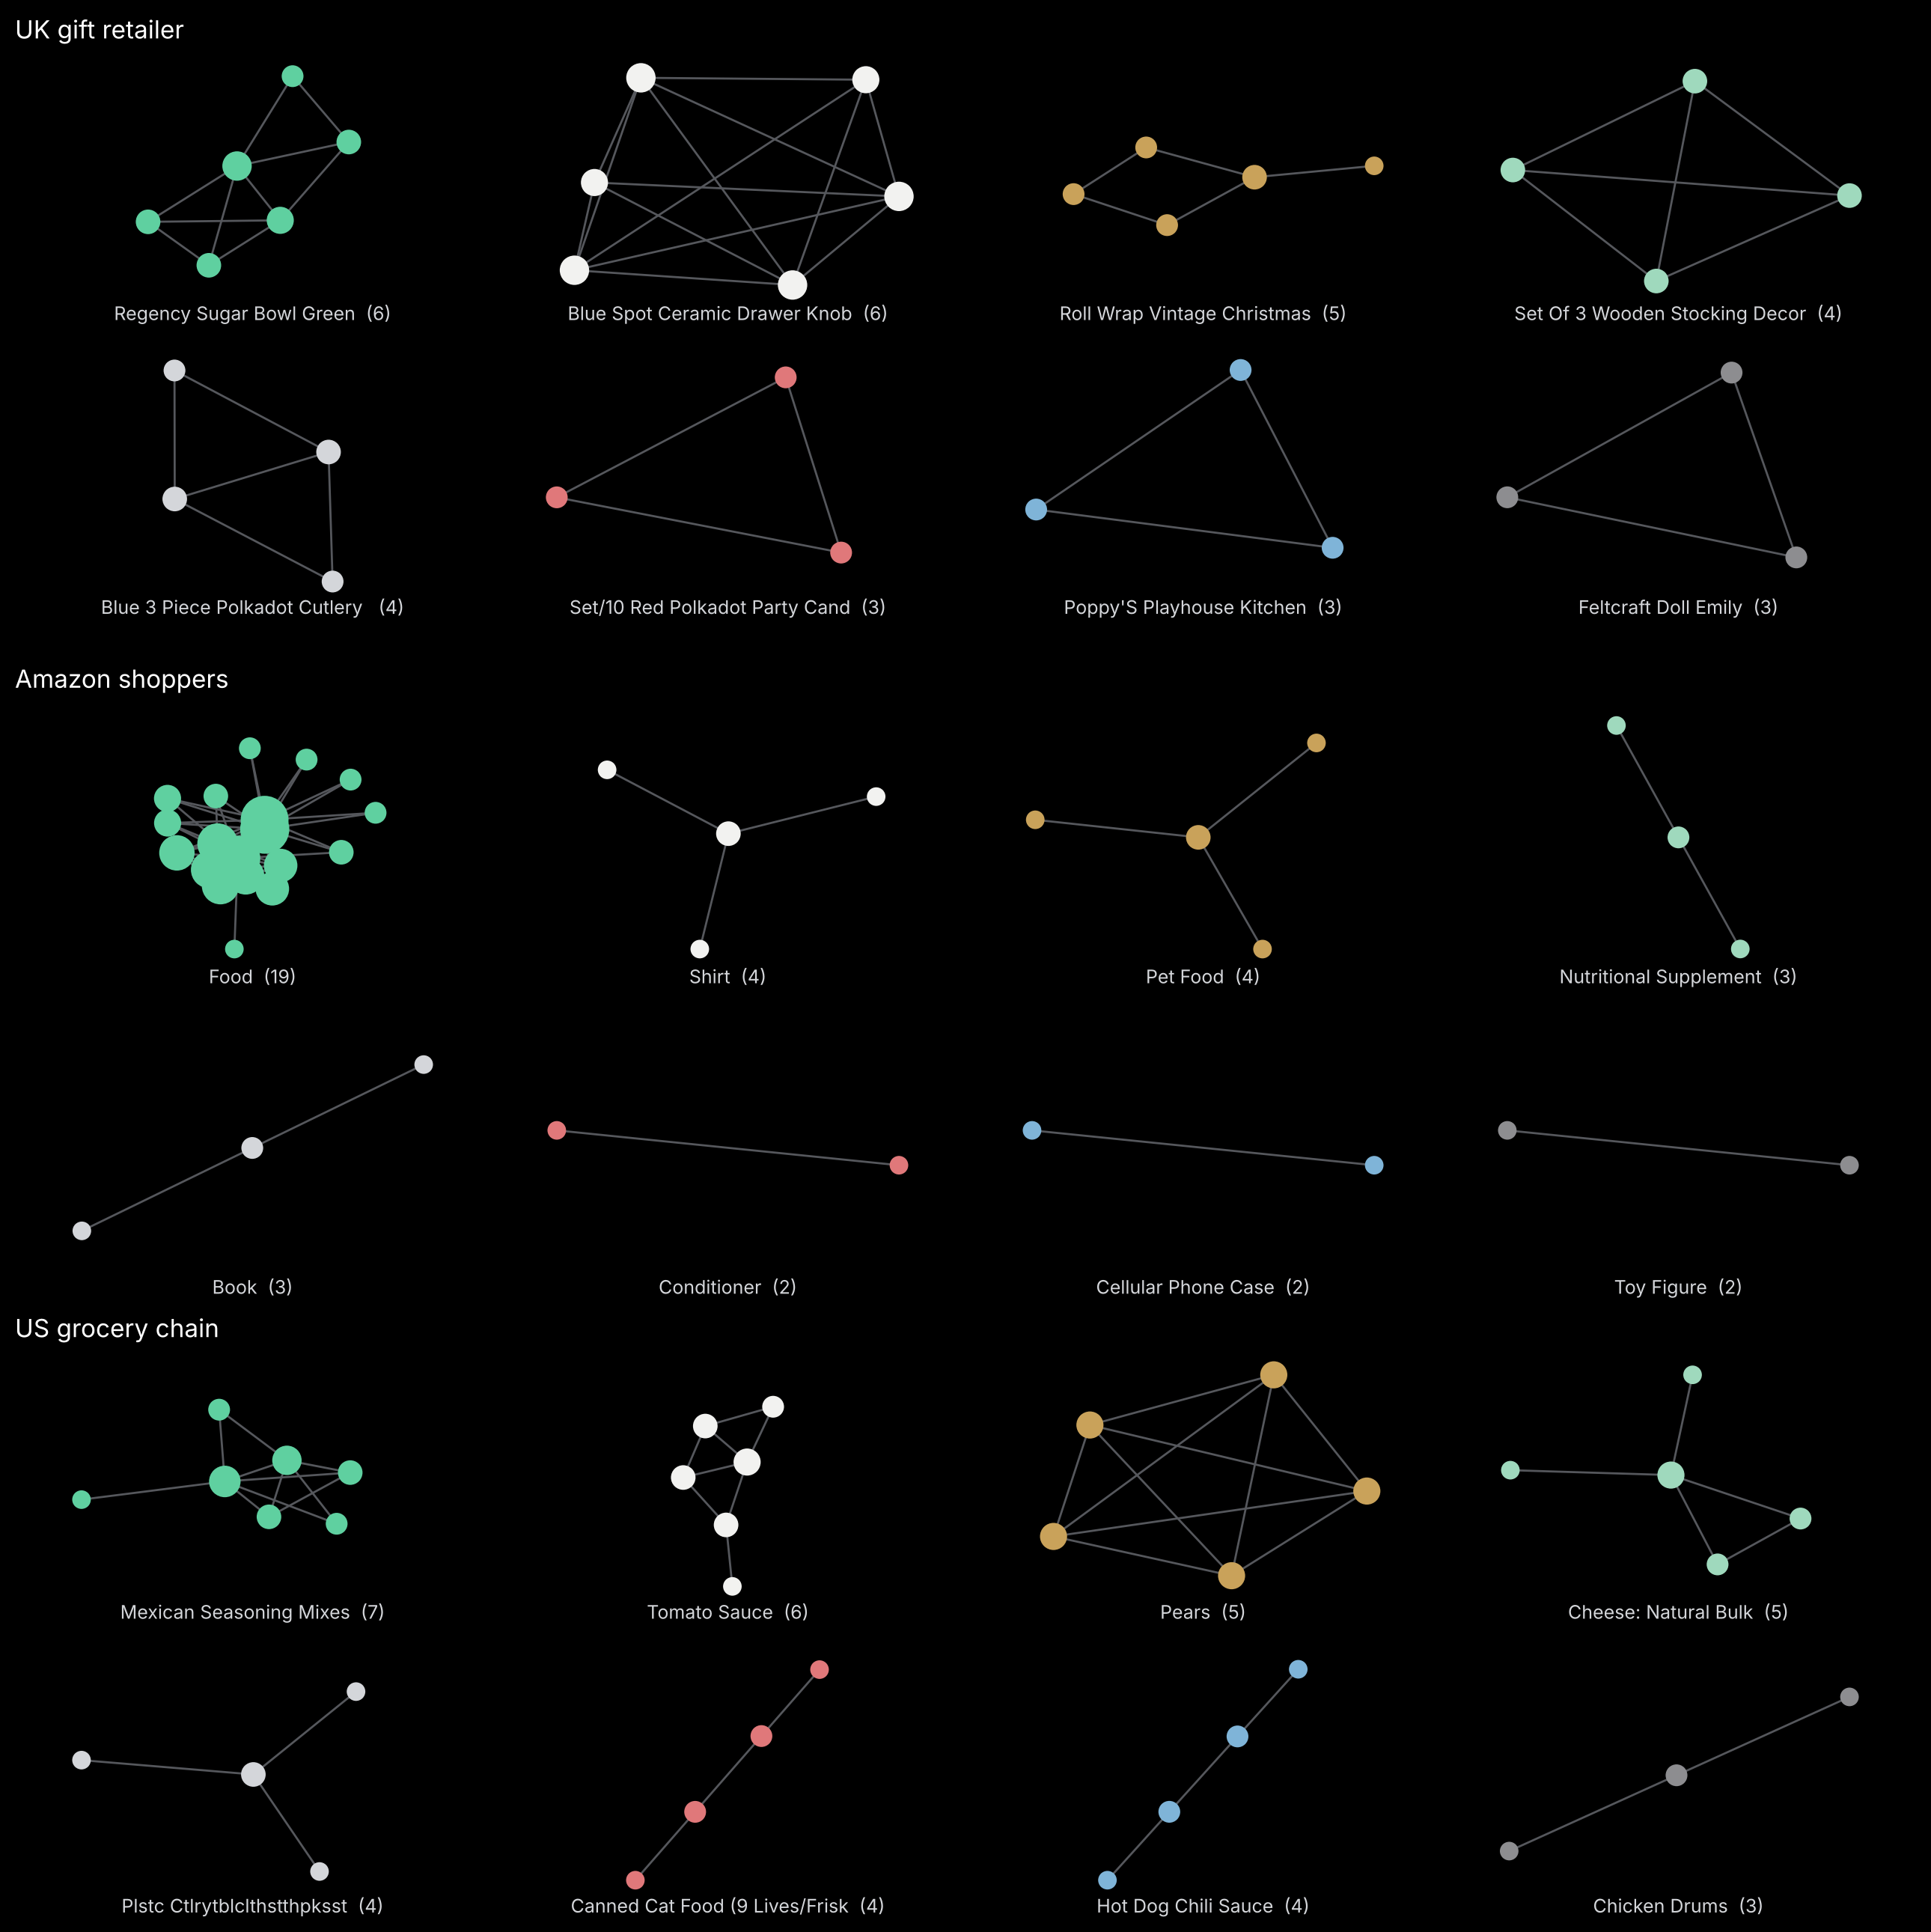

In [6]:
def draw_families(found, ax, strongest=150, biggest=12, across=4):
    """Products as dots, strong pairs as lines, one cluster per family. Returns the families."""
    spots = families(found, strongest, biggest, across).set_index("name")
    palette = [JADE, WHITE, "#c9a25a", "#9fd9bd", SILVER, "#e0787a", "#7fb4d8", GREY]
    for a, b in zip(found.head(strongest).name_a, found.head(strongest).name_b):
        if a in spots.index:
            ax.plot(*zip(spots.loc[a, ["x", "y"]], spots.loc[b, ["x", "y"]]), color="#55575c", lw=1, zorder=1)
    ax.scatter(spots.x, spots.y, s=50 + 30 * spots.links, color=[palette[(f - 1) % 8] for f in spots.family], zorder=2, linewidths=0)
    for number, members in spots.groupby("family"):
        words = members.index[0].title().split()                       # name the family after its busiest product
        ax.text((number - 1) % across, -((number - 1) // across) - 0.47, " ".join(words)[:30] + f"  ({len(members)})", ha="center", fontsize=9, color=SILVER)
    ax.set_xlim(-0.5, across - 0.5); ax.axis("off")
    return spots

fig, axes = plt.subplots(3, 1, figsize=(13, 13))
for ax, (name, s) in zip(axes, shops.items()):
    draw_families(s["pairs"], ax, strongest=80, biggest=8); ax.set_title(short[name], loc="left", fontsize=12)
plt.tight_layout(); plt.show()

In [7]:
kept = {short[n]: f"{(s['pairs_next'].lift_after > 1).sum()} of {len(s['pairs_next'])}" for n, s in shops.items()}
pd.Series(kept, name="Strongest pairs still linked in the next 90 days").to_frame()

,Strongest pairs still linked in the next 90 days
UK gift retailer,50 of 50
Amazon shoppers,50 of 50
US grocery chain,50 of 50


Each shop's baskets tell a different story, and each one makes sense.

* **Gift shop:** sets sold as separate pieces. Tea plates, party candles, decorations.
* **Amazon:** the strongest links are groceries. Cheese, bread, poultry and vegetables arrive in the same order, which is Amazon's grocery delivery showing up inside a general store. Outside food, most Amazon orders hold one or two things, so there is little to pair.
* **Grocery chain:** the textbook cases. Cake mix and frosting, shampoo and conditioner, taco shells and taco seasoning.

At all three shops, every one of the 50 strongest pairs was still linked in the 90 days that were held back.

## What this says

* **The method carried over without changes.** Same code, three kinds of business, sensible results each time.
* **Customer segmentation is most useful where leaving is a real risk.** At a shop people visit by habit, it is a guide to spend more than to who will leave.
* **Market basket analysis is most useful where baskets are big.** Grocery baskets average nearly nine products and give thousands of pairs. Amazon orders average two and give under a hundred.
* **The newer data agrees with the old.** Nothing found in the 2011 gift shop was a quirk of its age.